# 8. A published model: the Beining granule cell

The earlier notebooks built biophysics by hand. A *published* model is a
different problem: someone else has already fitted several dozen conductances
across half a dozen regions, and the job is to reproduce their cell faithfully
and then vary it deliberately.

`pynetrees.gc_model` is the Python counterpart of `GC_initModel.m` from the
[Beining et al. (2017)](https://doi.org/10.1007/s00429-016-1338-2) Active GC
Model package. It splits the problem in two, and the split is the whole point:

| | MATLAB | here |
|---|---|---|
| *what goes where* | `GC_biophys.m` — 656 lines of `strfind(options, '-x')` **computing** a nested struct | `_gc_biophys.py` — the same table, simply **written down** |
| *applying it* | woven through the same 656 lines | `GC_init` |

A variant is therefore a **value**, not a flag string. Where MATLAB writes
`GC_biophys('-a-p-n-y')` and you read 656 lines to find out what `-y` changed,
here you write `spec.scaled({"Kir21": 0.5})` and `spec.diff(other)` tells you.

## What ships with the package

Everything the model needs except a compiler:

| | |
|---|---|
| `pt.GC_BIOPHYS` | the mechanism table — 11 regions, 570 parameters |
| `pt.gc_trees()` | the eight reconstructions it was fitted to |
| `pt.gc_mod_path()` | the 44 `.mod` sources, ready for `nrnivmodl` |

So §1 and §2 below need nothing but `pynetrees` and `neuron`. §3 runs the
active model, which needs those `.mod` files **compiled** — see the note there.

In [1]:
import numpy as np
import pynetrees as pt

print(f"{len(pt.GC_BIOPHYS)} regions in the bundled table")
print(f"{len(pt.gc_trees())} bundled morphologies")
print(f"{len(list(pt.gc_mod_path().glob('*.mod')))} bundled .mod sources")

C:\Users\felix\AppData\Local\Temp\ipykernel_34964\3054171660.py:2: UserWarning: pynetrees: 1 optional feature(s) unavailable in this environment.
  - Blender export: no bpy -> pynetrees.blender (not imported by `import pynetrees` in any case) will not work (pip install 'pynetrees[blender]')
  Install everything at once with: pip install 'pynetrees[blender]'
  Silence this with PYNETREES_NO_DEPENDENCY_WARNING=1.
  import pynetrees as pt


11 regions in the bundled table


8 bundled morphologies
44 bundled .mod sources


## 1. The specification, without a simulator

`gc_spec()` with no arguments *is* the published model. Nothing here imports
NEURON, so a variant can be built, compared and checked on any machine — which
is also why the variant logic is unit-tested rather than only exercised by a
simulation that takes a minute to run.

In [2]:
spec = pt.gc_spec()

print("name     :", spec.name)
print("celsius  :", spec.celsius, "degC")
print("regions  :", ", ".join(sorted(spec.regions)))
print()
print(f"{len(spec.channels)} active channels:")
print("  " + ", ".join(spec.channels))
print()
print("ion blocks:", spec.ion_blocks)

name     : GC_Beining2017
celsius  : 24.0 degC
regions  : GCL, SGCL, adendIML, adendMML, adendOML, all, axon, axonh, soma, spineshead, spinesneck

16 active channels:
  BK, Cabuffer, Cav12, Cav13, Cav22, Cav32, HCN, Kir21, Kv11, Kv14, Kv21, Kv34, Kv42, Kv723, SK2, na8st

ion blocks: ['ca_ion', 'k_ion', 'na_ion']


`spec.regions` is the raw table. `for_region` is what actually applies to a
region — the pseudo-region `"all"` merged in first, then the region's own
entries on top:

In [3]:
soma = spec.for_region("soma")
print("mechanisms on the soma:", ", ".join(sorted(soma)))
print()
print("its passive cable:", soma["pas"])
print("its sodium       :", {k: v for k, v in soma["na8st"].items()
                             if k in ("gbar", "vShift")})
print()
# inherited from `all`, which the soma does not override
print("ek inherited from 'all':", soma["k_ion"])

mechanisms on the soma: BK, Cabuffer, Cav12, Cav13, Cav22, Cav32, Kir21, Kv21, SK2, ca_ion, k_ion, na8st, na_ion, pas

its passive cable: {'cm': 0.9, 'Ra': 200.0, 'g': 1.3846153846153847e-05, 'e': -80.0}
its sodium       : {'vShift': 22.0, 'gbar': 0.088128}

ek inherited from 'all': {'ek': -93.0}


Merging is per **mechanism**, not per parameter: a region that names
`Cabuffer` replaces `all`'s entry outright rather than inheriting the
parameters it did not mention. That is what MATLAB's struct assignment does,
and half-inherited channel kinetics would be worse than either alternative.

### Variants are values

`GCSpec` is frozen — every adjustment returns a new spec, so a variant cannot
quietly change the one it came from, and the bundled table is never edited by
using it.

In [4]:
# the adult-born / newborn direction: less inward rectifier, more HCN
newborn = spec.scaled({"Kir21": 0.5, "HCN": 2.0})

# a sodium knockout, naming the parameter explicitly rather than scaling
# everything that looks like a conductance
no_na = spec.scaled({"na8st": {"gbar": 0.0}})

# the passive model -- ostruct.vmodel = 3
passive = pt.gc_spec(passive_only=True)

for label, variant in [("newborn", newborn), ("no_na", no_na), ("passive", passive)]:
    changed = variant.diff(spec)
    n = sum(len(params) for block in changed.values() for params in block.values())
    print(f"{label:8s} {len(variant.channels):2d} channels, {n:3d} parameter(s) differ")

newborn  16 channels,  14 parameter(s) differ
no_na    16 channels,   3 parameter(s) differ
passive   0 channels, 534 parameter(s) differ


`diff` answers the question the 656-line original cannot: *what does this
variant actually change?*

In [5]:
for region, block in newborn.diff(spec).items():
    for mech, params in block.items():
        for name, (mine, theirs) in params.items():
            print(f"  {region:10s} {mech:6s} {name:6s} "
                  f"{theirs:10.3e} -> {mine:10.3e}")

  GCL        Kir21  gkbar   1.416e-04 ->  7.078e-05
  adendIML   HCN    gbar    4.000e-06 ->  8.000e-06
  adendIML   Kir21  gkbar   1.416e-04 ->  7.078e-05
  adendMML   HCN    gbar    4.000e-06 ->  8.000e-06
  adendMML   Kir21  gkbar   1.416e-04 ->  7.078e-05
  adendOML   HCN    gbar    4.000e-06 ->  8.000e-06
  adendOML   Kir21  gkbar   1.416e-04 ->  7.078e-05
  axon       Kir21  gkbar   6.741e-05 ->  3.371e-05
  axonh      Kir21  gkbar   6.741e-05 ->  3.371e-05
  soma       Kir21  gkbar   1.416e-04 ->  7.078e-05
  spineshead HCN    gbar    4.000e-06 ->  8.000e-06
  spineshead Kir21  gkbar   1.416e-04 ->  7.078e-05
  spinesneck HCN    gbar    4.000e-06 ->  8.000e-06
  spinesneck Kir21  gkbar   1.416e-04 ->  7.078e-05


Scaling by mechanism only touches parameters whose names read as a conductance
density (`*bar`, `g`, `gbar`) — the same test `scale_spines.m` uses. Gating
shifts and rate constants are left alone:

In [6]:
before = spec.regions["adendMML"]["Kv42"]
after  = spec.scaled({"Kv42": 2.0}).regions["adendMML"]["Kv42"]
for name in ("gkbar", "vshift", "kci"):
    print(f"  {name:7s} {before[name]:>10.5g} -> {after[name]:>10.5g}"
          f"{'   <- doubled' if before[name] != after[name] else ''}")

  gkbar      0.00435 ->     0.0087   <- doubled
  vshift         -20 ->        -20
  kci        0.04873 ->    0.04873


For anything scaling cannot express, `overridden` replaces values outright,
parameter by parameter:

In [7]:
cold = pt.gc_spec(
    celsius=33.0,
    override={"soma": {"na8st": {"vShift": 12.0}},
              "all":  {"k_ion": {"ek": -85.0}}},
    name="warm_shifted",
)
print(f"{cold.name}: celsius {cold.celsius}, "
      f"soma na8st.vShift {cold.regions['soma']['na8st']['vShift']}, "
      f"ek {cold.regions['all']['k_ion']['ek']}")
print("bundled table untouched:",
      pt.GC_BIOPHYS["soma"]["na8st"]["vShift"], pt.GC_BIOPHYS["all"]["k_ion"]["ek"])

warm_shifted: celsius 33.0, soma na8st.vShift 12.0, ek -85.0
bundled table untouched: 22.0 -93.0


### Spine scaling

Granule-cell spines are not resolved in the reconstruction, so their membrane
is folded into `cm` and `g_pas` region by region (`GC_spinedensity.m` +
`scale_spines.m`). The bundled table **already has this applied** — it is the
`ostruct.scalespines = 1` model, and `adendMML.pas.cm = 1.71` gives it away,
since `0.9 × 1.9 = 1.71`.

Applying it twice is the obvious mistake, so `gc_spec` refuses:

In [8]:
print("GC_SPINE_DENSITY (added membrane as a fraction):")
for region, factor in pt.GC_SPINE_DENSITY.items():
    print(f"  {region:10s} {factor}")

print()
print("soma  cm =", spec.regions["soma"]["pas"]["cm"], " (no spines)")
print("MML   cm =", spec.regions["adendMML"]["pas"]["cm"],
      "= 0.9 x", 1 + pt.GC_SPINE_DENSITY["adendMML"] * 0.9)

print()
try:
    pt.gc_spec(spine_scale=0.9)
except ValueError as error:
    print("refused:", str(error).split(".")[0] + ".")

GC_SPINE_DENSITY (added membrane as a fraction):
  soma       0.0
  axon       0.0
  axonh      0.0
  GCL        0.0
  SGCL       0.0
  adendIML   0.5
  adendMML   1.0
  adendOML   1.0

soma  cm = 0.9  (no spines)
MML   cm = 1.71 = 0.9 x 1.9

refused: this spec already has spine scaling folded in (a MATLAB dump made with ostruct.


## 2. Building it

`GC_init` folds the passive parameters into `Ri`/`Gm`/`Cm`, builds the
sections, then inserts and parameterises everything else.

The order matters: NEURON's d-lambda rule reads `Ra` and `cm` to choose how
many compartments each section gets, so the passive cable has to be right
*before* the sections exist. Setting it afterwards — the tempting order, since
everything else is set on finished sections — leaves the compartment count
computed from the wrong cable.

Start with the passive variant, which needs only NEURON's built-in `pas`:

In [9]:
cell = pt.gc_tree()
print(cell)
print()
for index, region in enumerate(cell.rnames):
    print(f"  {region:14s} {int((cell.R == index).sum()):5d} nodes")

Tree(name='GC1', n_nodes=3765, regions=[axon, GCL, adendIML, adendMML, adendOML, adendOMLout, soma, axonh])



  axon            1592 nodes
  GCL              108 nodes
  adendIML         322 nodes
  adendMML        1123 nodes
  adendOML         583 nodes
  adendOMLout        0 nodes
  soma              11 nodes
  axonh             26 nodes


In [10]:
gc = pt.GC_init(cell, passive_only=True, cut_axon=True, strict=True)
print(gc.report())
print()
for region in ("soma", "GCL", "adendIML", "adendMML", "adendOML", "axonh"):
    sec = gc.region_sections[region][0]
    seg = next(iter(sec))
    print(f"  {region:10s} Ra={sec.Ra:6.1f}  cm={sec.cm:5.3f}  "
          f"g_pas={seg.pas.g:.3e}  e_pas={seg.pas.e:6.1f}")

GC_Beining2017: 2173 nodes -> 62 sections, 0 channel(s)

  soma       Ra= 200.0  cm=0.900  g_pas=1.385e-05  e_pas= -80.0
  GCL        Ra= 200.0  cm=0.900  g_pas=1.385e-05  e_pas= -80.0
  adendIML   Ra= 200.0  cm=1.305  g_pas=2.008e-05  e_pas= -80.0
  adendMML   Ra= 200.0  cm=1.710  g_pas=2.631e-05  e_pas= -80.0
  adendOML   Ra= 200.0  cm=1.710  g_pas=2.631e-05  e_pas= -80.0
  axonh      Ra= 200.0  cm=0.900  g_pas=6.593e-06  e_pas= -80.0


`cut_axon=True` is `ostruct.cut`: drop the `axon` region, keep the hillock
`axonh`. `strict=True` is why that call is trustworthy — it raises if **any**
parameter could not be applied.

Ask for the full active model without compiled mechanisms and it does not
pretend to have succeeded:

In [11]:
partial = pt.GC_init(cell, cut_axon=True)      # no mech_library=
print(partial.report())
print()
missing = sorted({mech for _, mech, _ in partial.skipped})
print(f"{len(partial.skipped)} parameters could not be applied, across "
      f"{len(missing)} mechanisms:")
print("  " + ", ".join(missing))

GC_Beining2017: 2173 nodes -> 62 sections, 16 channel(s); 347 parameter(s) skipped in ['BK', 'Cabuffer', 'Cav12', 'Cav13', 'Cav22', 'Cav32', 'HCN', 'Kir21', 'Kv11', 'Kv14', 'Kv21', 'Kv34', 'Kv42', 'Kv723', 'SK2', 'ca_ion', 'k_ion', 'na8st', 'na_ion']

347 parameters could not be applied, across 19 mechanisms:
  BK, Cabuffer, Cav12, Cav13, Cav22, Cav32, HCN, Kir21, Kv11, Kv14, Kv21, Kv34, Kv42, Kv723, SK2, ca_ion, k_ion, na8st, na_ion


That is the difference between a model that is wrong and a model that tells
you it is wrong.

## 3. The active model

The channels above are specific to this model — no NEURON installation has
`na8st` or `Kir21` — so they have to be compiled from the bundled sources
first. Once, per machine:

```bash
# Linux / macOS: writes ./x86_64 (or ./arm64)
nrnivmodl "$(python -c 'import pynetrees; print(pynetrees.gc_mod_path())')"
```

On **Windows** the equivalent is `mknrndll`, a GUI shipped with NEURON: point
it at the directory `pt.gc_mod_path()` prints, and it writes `nrnmech.dll`
beside the `.mod` files. Then pass whatever it produced as `mech_library=`.

In [12]:
from pathlib import Path

# Look for a compiled library next to the bundled sources, then in the
# conventional build-output locations.
CANDIDATES = [
    pt.gc_mod_path() / "nrnmech.dll",
    Path("x86_64"), Path("arm64"),
    Path("../tests/Active GC Model/lib_mech/nrnmech.dll"),
]
LIB = next((p for p in CANDIDATES if p.exists()), None)

print("compiled mechanisms:", LIB if LIB else "not found - section 3 will skip")
print("to build them:      nrnivmodl", pt.gc_mod_path())

compiled mechanisms: ..\tests\Active GC Model\lib_mech\nrnmech.dll
to build them:      nrnivmodl C:\Users\felix\Documents\GitHub\PyNeTREES-Toolbox\src\pynetrees\data\gc_mod


In [13]:
if LIB:
    gc = pt.GC_init(cell, cut_axon=True, mech_library=LIB)
    print(gc.report())
    print()
    for region in ("soma", "adendMML", "axonh"):
        seg = next(iter(gc.region_sections[region][0]))
        print(f"  {region:10s} ek={seg.ek:6.1f}  ena={seg.ena:6.2f}  "
              f"g_pas={seg.pas.g:.3e}")

GC_Beining2017: 2173 nodes -> 62 sections, 16 channel(s); 7 parameter(s) skipped in ['Kir21', 'Kv11']

  soma       ek= -93.0  ena= 87.76  g_pas=1.385e-05
  adendMML   ek= -93.0  ena= 87.76  g_pas=2.631e-05
  axonh      ek= -93.0  ena= 87.76  g_pas=6.593e-06


The seven remaining `skipped` entries are real: parameters present in the
published table that this particular compiled library does not have
(`Kir21.vshiftbb`, `Kv11.vshift`). Surfacing them beats ignoring them — it
says the table and the `.mod` files came from different versions of the model.

Now inject a current step at the soma:

In [14]:
if LIB:
    soma_node = int(np.flatnonzero(gc.model.tree.region_nodes("soma"))[0])

    t, v = pt.run_current_clamp(
        gc.model, at_node=soma_node, amp=0.09,
        delay=20, dur=100, tstop=200, v_init=gc.spec.v_init,
    )
    trace = v[soma_node]
    spikes = int(((trace[:-1] < 0) & (trace[1:] >= 0)).sum())
    print(f"rest {trace[:100].mean():6.1f} mV   peak {trace.max():6.1f} mV   "
          f"{spikes} spike(s)")

rest  -80.5 mV   peak   49.9 mV   3 spike(s)


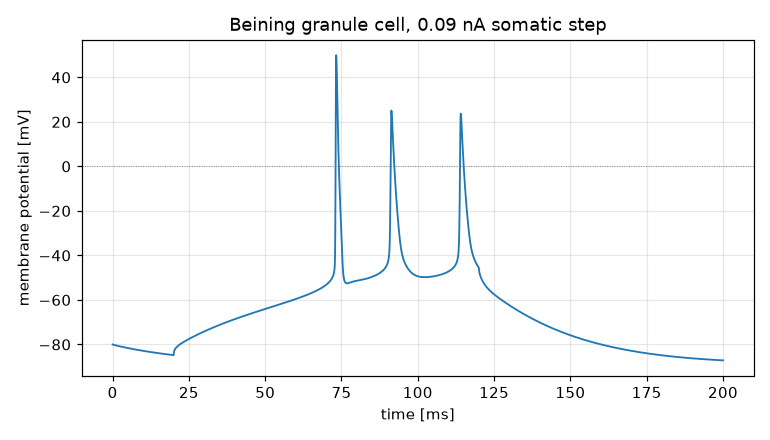

In [15]:
if LIB:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(t, trace, lw=1.2)
    ax.axhline(0, color="grey", lw=0.6, ls=":")
    ax.set_xlabel("time [ms]")
    ax.set_ylabel("membrane potential [mV]")
    ax.set_title("Beining granule cell, 0.09 nA somatic step")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig("tut08_gc_spikes.png", dpi=110)
    plt.close(fig)

    from IPython.display import Image
    display(Image("tut08_gc_spikes.png"))

### Comparing variants

Because a variant is a value, running one is the same call with a different
spec. Here the sodium knockout from section 1 — same morphology, same
everything else:

In [16]:
if LIB:
    knockout = pt.GC_init(cell, no_na, cut_axon=True, mech_library=LIB)
    node = int(np.flatnonzero(knockout.model.tree.region_nodes("soma"))[0])

    t_ko, v_ko = pt.run_current_clamp(
        knockout.model, at_node=node, amp=0.09,
        delay=20, dur=100, tstop=200, v_init=knockout.spec.v_init,
    )
    ko = v_ko[node]
    print(f"intact   peak {trace.max():6.1f} mV   "
          f"{int(((trace[:-1] < 0) & (trace[1:] >= 0)).sum())} spike(s)")
    print(f"no Na    peak {ko.max():6.1f} mV   "
          f"{int(((ko[:-1] < 0) & (ko[1:] >= 0)).sum())} spike(s)")

intact   peak   49.9 mV   3 spike(s)
no Na    peak  -39.5 mV   0 spike(s)


### A population

`GC_init` maps over lists like every other per-tree function, so the eight
bundled reconstructions are one call:

In [17]:
if LIB:
    models = pt.GC_init(pt.gc_trees()[:3], cut_axon=True, mech_library=LIB)
    for one in models:
        print(" ", one.report())

  GC_Beining2017: 2173 nodes -> 62 sections, 16 channel(s); 7 parameter(s) skipped in ['Kir21', 'Kv11']
  GC_Beining2017: 2729 nodes -> 64 sections, 16 channel(s); 7 parameter(s) skipped in ['Kir21', 'Kv11']
  GC_Beining2017: 2516 nodes -> 64 sections, 16 channel(s); 7 parameter(s) skipped in ['Kir21', 'Kv11']


## 4. Channel gradients

`insert_mechanism` takes a **callable** for any per-segment parameter,
evaluated with the path distance from the soma measured along the real cable
(NEURON's `h.distance`, not a straight line). That is the whole of a
distance-dependent density:

```python
pt.insert_mechanism(model, "hh", region="adendOML",
                    gnabar=lambda x: 0.12 * np.exp(-x / 200.0))
```

It also takes `nodes=` — tree node indices instead of, or intersected with, a
region name — so two parts of the *same* region can carry different densities
without splitting the region in the morphology first. Both are demonstrated in
[`04_neuron_simulation.ipynb`](04_neuron_simulation.ipynb).

## Where this leaves you

- `pt.gc_spec()` is the published table; `.scaled` / `.overridden` / `.without`
  derive variants and `.diff` says what changed.
- `pt.GC_init(tree)` builds it, and `strict=True` refuses to hand back a
  half-applied model.
- `pt.gc_trees()` and `pt.gc_mod_path()` are the morphologies and the
  mechanism sources, so nothing here depends on a path outside the package.
- `GCModel` behaves as a `NeuronModel` — `gc.loc(node)`, `gc.sections`,
  `gc.region_sections` — so everything in
  [`04_neuron_simulation.ipynb`](04_neuron_simulation.ipynb) applies unchanged.

What is deliberately **not** ported is `ostruct.usemorph`, MATLAB's catalogue
of 16 hard-coded `.mtr` paths. `pt.load_tree` reads all of them, and a number
that means "SH07 cells" only in one lab's directory layout is not an API.

**Back to:** [`04_neuron_simulation.ipynb`](04_neuron_simulation.ipynb)